# GIẢI THÍCH MÔ HÌNH BẰNG SHAP VÀ TRÍCH XUẤT GỢI Ý HÀNH ĐỘNG

In [1]:
import os
import re
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
PROC_DIR = os.path.join(ROOT, 'data', 'processed')
MODEL_DIR = os.path.join(ROOT, 'models')
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')

In [3]:
#Nếu đã có file test_pred_phobert.csv từ Colab thì đọc file đó, nếu chưa có thì đọc test_pred_baseline.csv
phobert_csv = os.path.join(PROC_DIR, 'test_pred_phobert.csv')
if os.path.exists(phobert_csv):
    df_test = pd.read_csv(phobert_csv)
    print('Đang dùng kết quả dự đoán từ PhoBERT Multi-Task')
else:
    df_test = pd.read_csv(os.path.join(PROC_DIR, 'test_pred_baseline.csv'))
    df_test['pred_sentiment'] = df_test['pred_sentiment_baseline']
    df_test['pred_topic'] = df_test['pred_topic_baseline']
    df_test['sentiment_conf'] = df_test['prob_sentiment_baseline']
    df_test['topic_conf'] = df_test['prob_topic_baseline']
    print('Chưa có file PhoBERT từ Colab -> dùng kết quả từ Baseline TF-IDF')

Đang dùng kết quả dự đoán từ PhoBERT Multi-Task


In [4]:
df_test['sentence_clean'] = df_test['sentence_clean'].fillna('')
df_test.head()

,sentence,sentiment,topic,sentence_clean,sentence_seg,pred_sentiment,pred_topic,sentiment_conf,topic_conf,needs_review
0,nói tiếng anh lưu loát .,2,0,nói tiếng anh lưu loát .,nói tiếng anh lưu loát .,2,0,0.8145,0.4835,True
1,giáo viên rất vui tính .,2,0,giáo viên rất vui tính .,giáo viên rất vui tính .,2,0,0.9075,0.8483,False
2,cô max có tâm .,2,0,cô max có tâm .,cô max có tâm .,2,0,0.9136,0.8148,False
3,"giảng bài thu hút , dí dỏm .",2,0,"giảng bài thu hút , dí dỏm .","giảng bài thu hút , dí dỏm .",0,0,0.5678,0.9085,True
4,"giáo viên không giảng dạy kiến thức , hướng dẫ...",0,0,"giáo viên không giảng dạy kiến_thức , hướng dẫ...","giáo viên không giảng dạy kiến_thức , hướng dẫ...",0,0,0.8231,0.8658,False


## 1. GIẢI THÍCH SHAP TOÀN CỤC VÀ CÁ NHÂN

In [5]:
import shap

tfidf = joblib.load(os.path.join(MODEL_DIR, 'tfidf_vectorizer.pkl'))
lr_sent = joblib.load(os.path.join(MODEL_DIR, 'lr_sentiment.pkl'))
df_train = pd.read_csv(os.path.join(PROC_DIR, 'train_clean.csv'))
df_train['sentence_clean'] = df_train['sentence_clean'].fillna('')

In [6]:
#Khởi tạo LinearExplainer trên tập train để xem những từ nào đẩy mạnh nhất về tiêu cực hoặc tích cực
X_tr = tfidf.transform(df_train['sentence_clean'])
X_te = tfidf.transform(df_test['sentence_clean'][:300])
explainer = shap.LinearExplainer(lr_sent, X_tr)
shap_vals = explainer.shap_values(X_te)

Background dataset has 11426 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=11426 when initializing the masker.


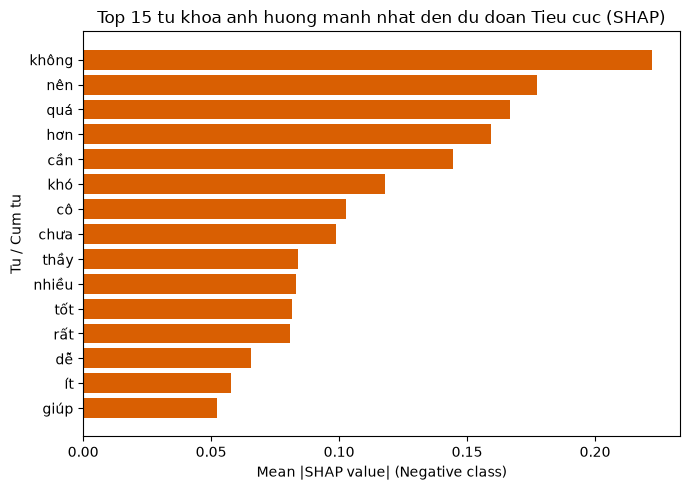

In [7]:
vocab = tfidf.get_feature_names_out()
#Lấy giá trị shap của lớp negative (index 0)
neg_shap = shap_vals[:, :, 0] if getattr(shap_vals, 'ndim', 0) == 3 else shap_vals[0]
mean_neg_contrib = np.abs(neg_shap).mean(axis=0)
top_idx = np.argsort(mean_neg_contrib)[-15:]

plt.figure(figsize=(7, 5))
plt.barh([vocab[i] for i in top_idx], mean_neg_contrib[top_idx], color='#d95f02')
plt.title('Top 15 tu khoa anh huong manh nhat den du doan Tieu cuc (SHAP)')
plt.xlabel('Mean |SHAP value| (Negative class)')
plt.ylabel('Tu / Cum tu')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'shap_top_negative_words.png'), dpi=150)
plt.show()

In [8]:
#Thử giải thích SHAP cho 1 câu phản hồi tiêu cực cụ thể khi giảng viên bấm xem trên App
tempt_row = df_test[df_test['pred_sentiment'] == 0].iloc[0]
tempt_text = tempt_row['sentence_clean']
tempt_text

'giảng bài thu hút , dí dỏm .'

In [9]:
vec_one = tfidf.transform([tempt_text])
sv_one = explainer.shap_values(vec_one)
sv_neg_one = sv_one[0, :, 0] if getattr(sv_one, 'ndim', 0) == 3 else sv_one[0][0]
nonzero_idx = vec_one.nonzero()[1]
word_imp = sorted([(vocab[i], float(sv_neg_one[i])) for i in nonzero_idx], key=lambda x: -abs(x[1]))
word_imp

[('giảng bài', -0.28630194235100126),
 ('thu', 0.1070820818866356),
 ('bài thu', 0.08217312883598894),
 ('bài', -0.061833236779782724),
 ('thu hút', 0.06119225201625558),
 ('dí', -0.04685059843512091),
 ('dí dỏm', -0.04685059843512091),
 ('dỏm', -0.04685059843512091),
 ('hút', 0.04045395704796553),
 ('giảng', -0.02127185740757238)]

## 2. GOM CỤM CÂU TIÊU CỰC VÀ TRÍCH XUẤT GỢI Ý HÀNH ĐỘNG CHO GIẢNG VIÊN

In [10]:
#Lọc các câu bị dự đoán là tiêu cực (pred_sentiment == 0)
df_neg = df_test[df_test['pred_sentiment'] == 0].copy()
df_neg['pred_topic'].value_counts()

pred_topic
0    707
1    526
2    152
3     39
Name: count, dtype: int64

In [11]:
#Bộ từ khóa khía cạnh theo từng chủ đề để gom nhóm vấn đề và sinh đề xuất hành động
aspect_rules = [
    (0, 'lecturer', 'Phương pháp giảng dạy & truyền đạt', ['khó hiểu', 'nhanh', 'buồn ngủ', 'nhàm chán', 'mơ hồ'], 'Rà soát tốc độ giảng, bổ sung ví dụ minh họa và hỏi đáp cuối buổi'),
    (0, 'lecturer', 'Tác phong & giờ giấc giảng viên', ['đi trễ', 'nghỉ', 'báo nghỉ', 'trễ giờ', 'thái độ', 'khó tính'], 'Đảm bảo lịch lên lớp đúng giờ và thông báo sớm khi thay đổi lịch'),
    (1, 'training_program', 'Khối lượng bài tập & độ khó đề thi', ['bài tập', 'quá nhiều', 'nặng', 'đề thi', 'khó', 'quá sức'], 'Cân đối lại khối lượng bài tập về nhà và cung cấp đề cương ôn tập rõ ràng'),
    (1, 'training_program', 'Giáo trình, slide & tài liệu học tập', ['tài liệu', 'slide', 'giáo trình', 'cũ', 'sơ sài', 'tiếng anh'], 'Cập nhật lại slide bài giảng và cung cấp tài liệu tham khảo tiếng Việt trước buổi học'),
    (1, 'training_program', 'Thời lượng thực hành & lý thuyết', ['thực hành', 'phòng lab', 'ít tiết', 'thời lượng', 'lý thuyết'], 'Tăng thời lượng hướng dẫn thực hành trực tiếp và chữa bài mẫu'),
    (2, 'facility', 'Thiết bị trình chiếu & âm thanh', ['máy chiếu', 'mic', 'loa', 'mờ', 'hư', 'hỏng'], 'Báo bộ phận quản trị thiết bị kiểm tra/thay mới máy chiếu và micro phòng học'),
    (2, 'facility', 'Nhiệt độ phòng học & điều hòa', ['nóng', 'máy lạnh', 'điều hòa', 'quạt', 'ngột ngạt'], 'Kiểm tra hệ thống điều hòa/quạt thông gió tại phòng học trước giờ lên lớp'),
    (2, 'facility', 'Cấu hình máy tính phòng thực hành', ['phòng máy', 'máy tính', 'chậm', 'lag', 'mạng', 'wifi'], 'Nâng cấp cấu hình hoặc cài đặt lại phần mềm tại phòng máy thực hành')
]

In [12]:
insights = []
for top_id, top_name, issue_name, kws, action_text in aspect_rules:
    sub = df_neg[df_neg['pred_topic'] == top_id]
    pattern = '|'.join([re.escape(k) for k in kws])
    matched = sub[sub['sentence_clean'].str.contains(pattern, case=False, na=False)]
    if len(matched) > 0:
        examples = matched['sentence'].head(2).tolist()
        insights.append({
            'topic_label': top_name,
            'issue_group': issue_name,
            'negative_count': len(matched),
            'matched_keywords': ', '.join(kws[:4]),
            'sample_feedback': ' | '.join(examples),
            'recommended_action': action_text
        })

df_insights = pd.DataFrame(insights).sort_values(by='negative_count', ascending=False)
df_insights

,topic_label,issue_group,negative_count,matched_keywords,sample_feedback,recommended_action
0,lecturer,Phương pháp giảng dạy & truyền đạt,82,"khó hiểu, nhanh, buồn ngủ, nhàm chán",có đôi lúc nói hơi nhanh làm sinh viên không t...,"Rà soát tốc độ giảng, bổ sung ví dụ minh họa v..."
2,training_program,Khối lượng bài tập & độ khó đề thi,75,"bài tập, quá nhiều, nặng, đề thi",học thì quá ít nhưng khi thi thì quá nhiều yêu...,Cân đối lại khối lượng bài tập về nhà và cung ...
3,training_program,"Giáo trình, slide & tài liệu học tập",66,"tài liệu, slide, giáo trình, cũ",tính thực tế cũng cao so với việc thi lý thuyế...,Cập nhật lại slide bài giảng và cung cấp tài l...
5,facility,Thiết bị trình chiếu & âm thanh,54,"máy chiếu, mic, loa, mờ",em học bên chất lượng cao mà phòng máy không c...,Báo bộ phận quản trị thiết bị kiểm tra/thay mớ...
1,lecturer,Tác phong & giờ giấc giảng viên,53,"đi trễ, nghỉ, báo nghỉ, trễ giờ","nghỉ nhiều quá , học bù thì khiến giờ giấc khô...",Đảm bảo lịch lên lớp đúng giờ và thông báo sớm...
7,facility,Cấu hình máy tính phòng thực hành,24,"phòng máy, máy tính, chậm, lag",cần thay đổi hệ thống máy tính ở một số phòng ...,Nâng cấp cấu hình hoặc cài đặt lại phần mềm tạ...
6,facility,Nhiệt độ phòng học & điều hòa,14,"nóng, máy lạnh, điều hòa, quạt",thiết bị phòng học như quạt máy cần phải đầu t...,Kiểm tra hệ thống điều hòa/quạt thông gió tại ...
4,training_program,Thời lượng thực hành & lý thuyết,6,"thực hành, phòng lab, ít tiết, thời lượng",thời lượng kiến thức trong một buổi học quá dà...,Tăng thời lượng hướng dẫn thực hành trực tiếp ...


In [13]:
df_insights.to_csv(os.path.join(PROC_DIR, 'actionable_insights.csv'), index=False, encoding='utf-8-sig')
print('Đã lưu bảng gợi ý hành động vào data/processed/actionable_insights.csv')

Đã lưu bảng gợi ý hành động vào data/processed/actionable_insights.csv
